# DSC 411/511 Project
# Notebook 06: RQ4 (new): Which Combinations of Building, Policy and Storm Traits Travel with Large Losses?

**Class topics:** Lecture 11 (claims as baskets, frequent itemsets, Apriori, FP-Growth, why confidence alone
fools you, checking a new record), Lecture 12 (lift, leverage, conviction, chi-squared), Lecture 03
(discretization and binarization).

---

**How this question was derived.** RQ1 and RQ2 gave us models that rank claims well, but a LightGBM model with
60 features is hard to hand to a claims manager. Association rules give the opposite: short, readable
"if A and B then C" statements. Lecture 11 used houses as baskets of features; we use **claims as baskets of
traits**, and add outcome items to the basket.

> **RQ4. Which combinations of building, policy and storm traits co-occur with large losses (and with
> unpaid claims) much more often than chance, and do these rules hold on new storms?**

---
# Section 0: Setup

In [1]:
import sys
import time
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 120)

claims = load_clean_claims()
print(f'Claims: {len(claims):,}')

Claims: 252,410


---
# Section 1: Claims as Baskets (Lecture 11, Section 1)

Association rules need **yes/no items**. So every useful column is discretized (Lecture 03, Section 4) into a
few meaningful bins. We choose the cut points from domain knowledge, not equal widths, because equal-width
bins on skewed data put almost everything in one bin (the "equal width trap").

| Item family | Items | Source |
|---|---|---|
| flood zone | `zone=V`, `zone=A`, `zone=X` | NFIP |
| building | `elevated`, `basement`, `slab`, `one_floor`, `mobile_home`, `condo_or_multiunit`, `built_pre1975`, `built_after2010` | NFIP |
| policy | `second_home`, `high_deductible(>=5k)`, `coverage<100k`, `coverage_at_250k_cap+`, `RR2_rated`, `CRS_discount` | NFIP |
| storm | `storm<=50km`, `storm<=200km`, `no_storm`, `cat3plus_at_closest` | HURDAT2 |
| rain | `rain3d>=200mm`, `rain3d<25mm` | PRISM |
| coast | `coast<=2km`, `coast>50km` | Natural Earth |
| neighbourhood | `income_low_quintile`, `income_high_quintile` | ACS |
| **outcome** | `OUT_large_loss`, `OUT_not_paid` | target (only on the right side of a rule) |

In [2]:
income_quintiles = claims['acs_median_household_income'].quantile([0.2, 0.8])
baskets = pd.DataFrame({
    'zone=V': claims['flood_zone_group'] == 'V_coastal_high_hazard',
    'zone=A': claims['flood_zone_group'] == 'A_special_flood_hazard',
    'zone=X': claims['flood_zone_group'] == 'X_moderate_or_minimal',
    'elevated': claims['elevatedBuildingIndicator'] == 1,
    'basement': claims['basement_group'].isin(['finished_basement', 'unfinished_basement']) | (claims['foundation_group'] == 'basement'),
    'slab': claims['foundation_group'] == 'slab',
    'one_floor': claims['floors_group'] == 'one_floor',
    'mobile_home': claims['occupancy_group'] == 'mobile_home',
    'condo_or_multiunit': claims['occupancy_group'].isin(['condo_association', 'unit_in_multi_unit_building', 'multi_family_5plus', 'multi_family_2to4']),
    'built_pre1975': claims['construction_year'] < 1975,
    'built_after2010': claims['construction_year'] > 2010,
    'second_home': claims['primaryResidenceIndicator'] == 0,
    'high_deductible(>=5k)': claims['building_deductible_usd'] >= 5000,
    'coverage<100k': claims['totalBuildingInsuranceCoverage'] < 100_000,
    'coverage_at_250k_cap+': claims['totalBuildingInsuranceCoverage'] >= 250_000,
    'RR2_rated': claims['rated_by_risk_rating_2'] == 1,
    'CRS_discount': claims['crsClassCode'] <= 6,
    'storm<=50km': claims['storm_distance_km'] <= 50,
    'storm<=200km': claims['storm_distance_km'] <= 200,
    'no_storm': claims['no_storm_within_window'] == 1,
    'cat3plus_at_closest': claims['storm_category_at_closest'] >= 3,
    'rain3d>=200mm': claims['rain_3day_mm'] >= 200,
    'rain3d<25mm': claims['rain_3day_mm'] < 25,
    'coast<=2km': claims['coast_distance_km'] <= 2,
    'coast>50km': claims['coast_distance_km'] > 50,
    'income_low_quintile': claims['acs_median_household_income'] <= income_quintiles[0.2],
    'income_high_quintile': claims['acs_median_household_income'] >= income_quintiles[0.8],
    'OUT_large_loss': claims['large_loss_flag'] == 1,
    'OUT_not_paid': claims['building_paid_flag'] == 0,
}).astype(bool)
NFIP_ITEMS = ['zone=V', 'zone=A', 'zone=X', 'elevated', 'basement', 'slab', 'one_floor', 'mobile_home', 'condo_or_multiunit',
              'built_pre1975', 'built_after2010', 'second_home', 'high_deductible(>=5k)', 'coverage<100k', 'coverage_at_250k_cap+',
              'RR2_rated', 'CRS_discount']
EXTERNAL_ITEMS = ['storm<=50km', 'storm<=200km', 'no_storm', 'cat3plus_at_closest', 'rain3d>=200mm', 'rain3d<25mm',
                  'coast<=2km', 'coast>50km', 'income_low_quintile', 'income_high_quintile']
OUTCOME_ITEMS = ['OUT_large_loss', 'OUT_not_paid']
item_support = (baskets.mean() * 100).round(1).sort_values(ascending=False)
print('Share of claims that contain each item (%):')
print(item_support.to_string())

Share of claims that contain each item (%):
RR2_rated                90.6
zone=A                   77.5
storm<=200km             66.3
coverage_at_250k_cap+    64.7
one_floor                61.3
slab                     54.7
CRS_discount             53.3
built_pre1975            50.9
cat3plus_at_closest      46.4
coast<=2km               34.5
second_home              32.0
high_deductible(>=5k)    30.8
storm<=50km              26.5
rain3d>=200mm            23.8
elevated                 21.1
income_high_quintile     20.0
income_low_quintile      20.0
zone=X                   18.3
no_storm                 17.7
coast>50km               16.8
OUT_not_paid             16.7
basement                 13.3
condo_or_multiunit       13.0
OUT_large_loss           11.6
coverage<100k            10.3
rain3d<25mm               6.1
built_after2010           4.7
zone=V                    3.9
mobile_home               2.4


### A warning before we mine anything (Lecture 11)

Some items are very common (`zone=A`, `one_floor`, `RR2_rated`). A rule that ends in a common item will have high
confidence just because the item is common. That is why we will not trust confidence alone.

---
# Section 2: Frequent Itemsets: Apriori vs FP-Growth (Lecture 11, Sections 2 and 4)

**Apriori** grows itemsets level by level: first single items, then pairs built only from frequent items, then
triples from frequent pairs, and so on. It relies on the **Apriori principle**: if an itemset is rare, every bigger
set that contains it is also rare, so it can be pruned. **FP-Growth** compresses the baskets into a prefix tree and
mines it without generating candidates.

We mine the **training years (2020-2023)** and keep the test years (2024-2025) to check the rules later.

In [3]:
train_baskets = baskets[claims['loss_year'].isin(TRAIN_YEARS).values]
test_baskets = baskets[claims['loss_year'].isin(TEST_YEARS).values]
MIN_SUPPORT = 0.01      # at least 1% of claims (about 1,500)
MAX_LENGTH = 4

timing_rows = []
timing_sample = train_baskets.sample(40_000, random_state=SEED)
for algorithm_name, algorithm in [('Apriori', apriori), ('FP-Growth', fpgrowth)]:
    start = time.time()
    itemsets = algorithm(timing_sample, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LENGTH)
    timing_rows.append({'algorithm': algorithm_name, 'seconds (40k claims)': round(time.time() - start, 1), 'itemsets_found': len(itemsets)})
print(pd.DataFrame(timing_rows).to_string(index=False))

algorithm  seconds (40k claims)  itemsets_found
  Apriori                   1.2            5923
FP-Growth                   0.6            5923


Both algorithms find exactly the same itemsets; only the speed differs. Lecture 11 explained when FP-Growth loses:
with few items and dense baskets the tree compresses badly. Here the items are dense too, so the gap is small.
We use FP-Growth on all training claims.

In [4]:
start = time.time()
frequent_itemsets = fpgrowth(train_baskets, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LENGTH)
print(f'Frequent itemsets (train, support >= {MIN_SUPPORT}): {len(frequent_itemsets):,} in {time.time() - start:.0f} s')
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(len)
print(frequent_itemsets['length'].value_counts().sort_index().to_string())

Frequent itemsets (train, support >= 0.01): 5,957 in 2 s
length
1      29
2     336
3    1679
4    3913


---
# Section 3: From Itemsets to Rules, and the Measures (Lecture 11 Section 3, Lecture 12 Sections 2-6)

For a rule A -> C:

| Measure | Formula | Meaning |
|---|---|---|
| support | P(A and C) | how often the whole rule occurs |
| confidence | P(C given A) | how often C happens when A happens |
| **lift** | confidence / P(C) | how many times more likely C is when A holds; 1 = independent |
| **leverage** | P(A and C) - P(A) P(C) | extra co-occurrence in absolute terms; small for rare rules |
| **conviction** | (1 - P(C)) / (1 - confidence) | how much more often the rule would be wrong if A and C were independent |
| **chi-squared** | sum over the 2x2 table of (observed - expected)^2 / expected | is the association more than chance? |

We keep only rules whose right side is a **single outcome item**.

In [5]:
all_rules = association_rules(frequent_itemsets, metric='lift', min_threshold=1.0)
outcome_rules = all_rules[all_rules['consequents'].apply(lambda c: len(c) == 1 and next(iter(c)) in OUTCOME_ITEMS)]
outcome_rules = outcome_rules[~outcome_rules['antecedents'].apply(lambda a: any(item in OUTCOME_ITEMS for item in a))].copy()
outcome_rules['rule'] = outcome_rules['antecedents'].apply(lambda a: ' & '.join(sorted(a))) + '  ->  ' + \
                        outcome_rules['consequents'].apply(lambda c: next(iter(c)))
outcome_rules['outcome'] = outcome_rules['consequents'].apply(lambda c: next(iter(c)))
outcome_rules['uses_external_items'] = outcome_rules['antecedents'].apply(lambda a: any(item in EXTERNAL_ITEMS for item in a))
n_train = len(train_baskets)


def chi_squared_for_rule(support_ac, support_a, support_c, n):
    """2x2 chi-squared from supports (Lecture 12, Section 5)."""
    observed = np.array([[support_ac, support_a - support_ac],
                         [support_c - support_ac, 1 - support_a - support_c + support_ac]]) * n
    expected = np.outer([support_a, 1 - support_a], [support_c, 1 - support_c]) * n
    return ((observed - expected) ** 2 / expected).sum()


outcome_rules['chi_squared'] = [chi_squared_for_rule(row['support'], row['antecedent support'], row['consequent support'], n_train)
                                for _, row in outcome_rules.iterrows()]
print(f'Rules with an outcome on the right: {len(outcome_rules):,}')

Rules with an outcome on the right: 770


## 3.1 Why confidence alone will fool you

Sort the not-paid rules by confidence, then by lift, and compare.

In [6]:
columns_to_show = ['rule', 'support', 'confidence', 'lift', 'leverage', 'conviction', 'chi_squared']
not_paid_rules = outcome_rules[outcome_rules['outcome'] == 'OUT_not_paid']
print(f'Base rate of OUT_not_paid in train: {train_baskets["OUT_not_paid"].mean():.3f}')
print('\nTop 5 by CONFIDENCE:')
print(not_paid_rules.sort_values('confidence', ascending=False)[columns_to_show].head(5).round(3).to_string(index=False))
print('\nTop 5 by LIFT:')
print(not_paid_rules.sort_values('lift', ascending=False)[columns_to_show].head(5).round(3).to_string(index=False))

Base rate of OUT_not_paid in train: 0.193

Top 5 by CONFIDENCE:
                                                                  rule  support  confidence  lift  leverage  conviction  chi_squared
                                rain3d<25mm & zone=X  ->  OUT_not_paid    0.013       0.537 2.780     0.008       1.744     2744.486
                                  rain3d<25mm & slab  ->  OUT_not_paid    0.013       0.524 2.709     0.008       1.693     2551.971
                      RR2_rated & rain3d<25mm & slab  ->  OUT_not_paid    0.013       0.523 2.707     0.008       1.692     2541.039
         cat3plus_at_closest & storm<=200km & zone=X  ->  OUT_not_paid    0.016       0.476 2.461     0.009       1.539     2608.697
cat3plus_at_closest & coverage_at_250k_cap+ & zone=X  ->  OUT_not_paid    0.010       0.465 2.403     0.006       1.506     1589.972

Top 5 by LIFT:
                                                                  rule  support  confidence  lift  leverage  conviction  c

---
# Section 4: The Large-Loss Rules

In [7]:
large_rules = outcome_rules[outcome_rules['outcome'] == 'OUT_large_loss'].sort_values('lift', ascending=False)
print(f'Base rate of OUT_large_loss in train (all claims): {train_baskets["OUT_large_loss"].mean():.3f}')
print(large_rules[columns_to_show + ['uses_external_items']].head(20).round(3).to_string(index=False))
large_rules[columns_to_show + ['uses_external_items']].round(4).to_csv(TABLE_DIR / '06_rq4_large_loss_rules.csv', index=False)

Base rate of OUT_large_loss in train (all claims): 0.084
                                                                                  rule  support  confidence  lift  leverage  conviction  chi_squared  uses_external_items
  cat3plus_at_closest & condo_or_multiunit & coverage_at_250k_cap+  ->  OUT_large_loss    0.018       0.450 5.368     0.015       1.666    10777.888                 True
            cat3plus_at_closest & condo_or_multiunit & second_home  ->  OUT_large_loss    0.018       0.390 4.650     0.014       1.502     8819.553                 True
                 condo_or_multiunit & coverage_at_250k_cap+ & slab  ->  OUT_large_loss    0.017       0.384 4.584     0.013       1.488     7922.393                False
         CRS_discount & condo_or_multiunit & coverage_at_250k_cap+  ->  OUT_large_loss    0.017       0.378 4.503     0.014       1.472     8035.838                False
                   cat3plus_at_closest & condo_or_multiunit & slab  ->  OUT_large_loss    0.0

## 4.1 NFIP-only rules vs rules that may use external items

The progression again: if we only allow NFIP building and policy items, how strong can a large-loss rule get?

In [8]:
progression_rows = []
for outcome in OUTCOME_ITEMS:
    for allowed, mask in [('NFIP items only', ~outcome_rules['uses_external_items']), ('NFIP + external items', outcome_rules['uses_external_items'] | True)]:
        subset = outcome_rules[(outcome_rules['outcome'] == outcome) & mask]
        top10 = subset.sort_values('lift', ascending=False).head(10)
        progression_rows.append({'outcome': outcome, 'allowed items': allowed, 'n_rules': len(subset),
                                 'best_lift': subset['lift'].max(), 'mean_lift_top10': top10['lift'].mean(),
                                 'best_confidence': subset['confidence'].max()})
progression_table = pd.DataFrame(progression_rows).round(3)
progression_table.to_csv(TABLE_DIR / '06_rq4_progression.csv', index=False)
print(progression_table.to_string(index=False))

       outcome         allowed items  n_rules  best_lift  mean_lift_top10  best_confidence
OUT_large_loss       NFIP items only      149      4.584            4.036            0.384
OUT_large_loss NFIP + external items      450      5.368            4.443            0.450
  OUT_not_paid       NFIP items only       96      1.836            1.678            0.355
  OUT_not_paid NFIP + external items      320      2.780            2.481            0.537


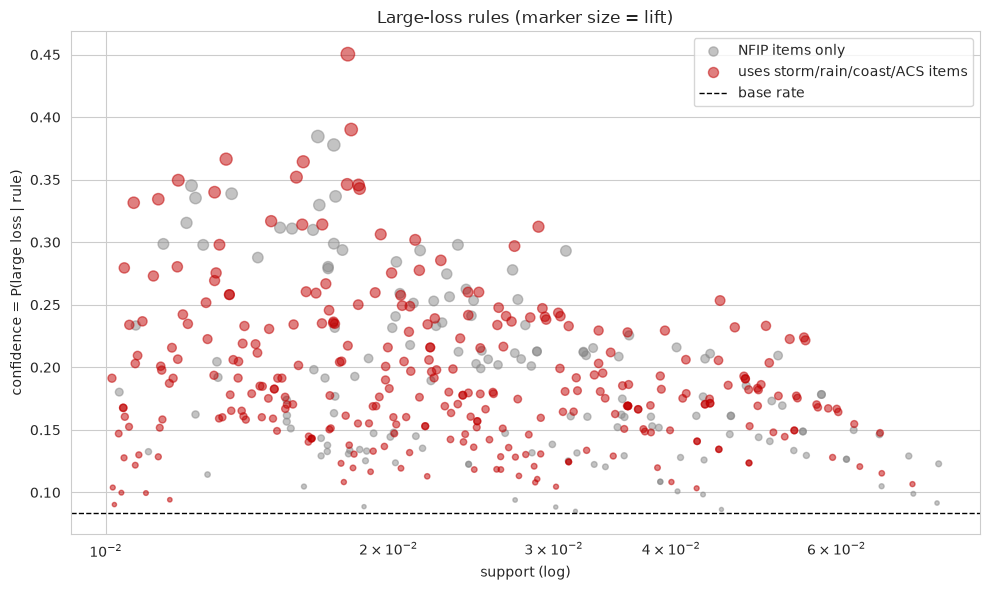

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
for uses_external, color, label in [(False, '#888888', 'NFIP items only'), (True, '#C00000', 'uses storm/rain/coast/ACS items')]:
    subset = large_rules[large_rules['uses_external_items'] == uses_external]
    ax.scatter(subset['support'], subset['confidence'], s=8 + 20 * (subset['lift'] - 1), alpha=0.5, color=color, label=label)
ax.axhline(train_baskets['OUT_large_loss'].mean(), color='k', ls='--', lw=1, label='base rate')
ax.set_xscale('log')
ax.set_xlabel('support (log)')
ax.set_ylabel('confidence = P(large loss | rule)')
ax.set_title('Large-loss rules (marker size = lift)')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / '06_rq4_rules_scatter.png', dpi=120)
plt.show()

---
# Section 5: All Measures, Side by Side (Lecture 12, Section 6)

Do the measures agree on which rules are "best"? We rank the large-loss rules by each measure and compare the
rankings with Spearman correlation.

In [10]:
ranking = large_rules[['support', 'confidence', 'lift', 'leverage', 'conviction', 'chi_squared']]
print(ranking.corr(method='spearman').round(2).to_string())

             support  confidence  lift  leverage  conviction  chi_squared
support         1.00       -0.27 -0.27      0.79       -0.27         0.41
confidence     -0.27        1.00  1.00      0.30        1.00         0.72
lift           -0.27        1.00  1.00      0.30        1.00         0.72
leverage        0.79        0.30  0.30      1.00        0.30         0.85
conviction     -0.27        1.00  1.00      0.30        1.00         0.72
chi_squared     0.41        0.72  0.72      0.85        0.72         1.00


**Reading the table.** Lift, confidence and conviction rank rules almost the same way (for a fixed outcome they
are monotone transformations of each other). Leverage and chi-squared also reward **support**: they prefer
broad, common rules. Lecture 12's point holds: pick the measure that matches the use. For triage we want high lift
with enough support to matter, so we sort by lift and require support >= 1%.

---
# Section 6: Do the Rules Hold on New Storms? (2024-2025)

A rule mined on 2020-2023 is only useful if it still holds on Helene and Milton. We recompute confidence and lift of
the top rules on the test years.

In [11]:
def evaluate_rule_on(baskets_frame, antecedent, outcome):
    has_antecedent = baskets_frame[list(antecedent)].all(axis=1)
    base_rate = baskets_frame[outcome].mean()
    confidence = baskets_frame.loc[has_antecedent, outcome].mean() if has_antecedent.any() else np.nan
    return has_antecedent.mean(), confidence, confidence / base_rate


holdout_rows = []
for _, rule in pd.concat([large_rules.head(12), not_paid_rules.sort_values('lift', ascending=False).head(6)]).iterrows():
    support_test, confidence_test, lift_test = evaluate_rule_on(test_baskets, rule['antecedents'], rule['outcome'])
    holdout_rows.append({'rule': rule['rule'], 'train_lift': rule['lift'], 'test_lift': lift_test,
                         'train_confidence': rule['confidence'], 'test_confidence': confidence_test, 'test_support': support_test})
holdout_table = pd.DataFrame(holdout_rows).round(3)
holdout_table.to_csv(TABLE_DIR / '06_rq4_rules_on_test_years.csv', index=False)
print(f'Base rates in test: large loss {test_baskets["OUT_large_loss"].mean():.3f}, not paid {test_baskets["OUT_not_paid"].mean():.3f}')
print(holdout_table.to_string(index=False))

Base rates in test: large loss 0.161, not paid 0.131
                                                                                  rule  train_lift  test_lift  train_confidence  test_confidence  test_support
  cat3plus_at_closest & condo_or_multiunit & coverage_at_250k_cap+  ->  OUT_large_loss       5.368      2.125             0.450            0.343         0.078
            cat3plus_at_closest & condo_or_multiunit & second_home  ->  OUT_large_loss       4.650      1.848             0.390            0.298         0.088
                 condo_or_multiunit & coverage_at_250k_cap+ & slab  ->  OUT_large_loss       4.584      2.831             0.384            0.456         0.058
         CRS_discount & condo_or_multiunit & coverage_at_250k_cap+  ->  OUT_large_loss       4.503      2.019             0.378            0.325         0.080
                   cat3plus_at_closest & condo_or_multiunit & slab  ->  OUT_large_loss       4.368      2.254             0.366            0.363        

**Reading the hold-out.** Confidence changes between periods because 2024 had many more large losses (base rate
16.1% vs 8.4%). **Lift** corrects for that, but the large-loss rules still **lose about half their lift** on the new
storms: the best rule falls from 5.4 to 2.1. Most rules stay clearly above 1 (1.7-2.8), so they still point to riskier
claims. One rule breaks completely: "category 3+ & condo/multi-unit & storm within 50 km" has lift 0.41 on 2024-2025.
Only 0.6% of test claims match it, and in 2024-2025 those condo claims close to a strong storm were mostly not large. The not-paid rules with little
rain become **stronger** (lift 2.8 to 3.7). Low rain is a stable sign of a weak claim.

---
# Section 7: Which Features Travel Together? Checking a New Record (Lecture 11, Sections 5-6)

Rules between **input** items describe the insured stock, and they can flag records that look wrong (data quality).

In [12]:
input_rules = all_rules[all_rules['antecedents'].apply(lambda a: not any(i in OUTCOME_ITEMS for i in a)) &
                        all_rules['consequents'].apply(lambda c: len(c) == 1 and not any(i in OUTCOME_ITEMS for i in c))]
strong_input_rules = input_rules[(input_rules['confidence'] >= 0.9) & (input_rules['lift'] >= 1.5)].sort_values('lift', ascending=False)
strong_input_rules = strong_input_rules.assign(rule=strong_input_rules['antecedents'].apply(lambda a: ' & '.join(sorted(a))) + '  ->  ' +
                                               strong_input_rules['consequents'].apply(lambda c: next(iter(c))))
print(strong_input_rules[['rule', 'support', 'confidence', 'lift']].head(10).round(3).to_string(index=False))

if len(strong_input_rules):
    example_rule = strong_input_rules.iloc[0]
    breaks_rule = baskets[list(example_rule['antecedents'])].all(axis=1) & ~baskets[next(iter(example_rule['consequents']))]
    print(f"\nClaims that break the strongest rule '{example_rule['rule']}': {breaks_rule.sum():,} "
          f"({breaks_rule.mean() * 100:.2f}%). These records deserve a second look.")

                                                                             rule  support  confidence  lift
       CRS_discount & condo_or_multiunit & coverage_at_250k_cap+  ->  second_home    0.043       0.936 2.968
cat3plus_at_closest & condo_or_multiunit & coverage_at_250k_cap+  ->  second_home    0.038       0.936 2.967
       CRS_discount & condo_or_multiunit & high_deductible(>=5k)  ->  second_home    0.021       0.935 2.964
cat3plus_at_closest & condo_or_multiunit & high_deductible(>=5k)  ->  second_home    0.021       0.933 2.956
                    CRS_discount & condo_or_multiunit & elevated  ->  second_home    0.015       0.925 2.931
           condo_or_multiunit & coverage_at_250k_cap+ & elevated  ->  second_home    0.022       0.920 2.918
               condo_or_multiunit & high_deductible(>=5k) & slab  ->  second_home    0.021       0.916 2.904
        condo_or_multiunit & high_deductible(>=5k) & storm<=50km  ->  second_home    0.016       0.915 2.901
        condo_or_mu

In [13]:
results_rq4 = {'progression': progression_table.to_dict('records'), 'top_large_loss_rules': large_rules[columns_to_show].head(10).round(4).to_dict('records'),
               'rules_on_test_years': holdout_table.to_dict('records')}
json.dump(results_rq4, open(TABLE_DIR / '06_rq4_results.json', 'w'), indent=2, default=str)

---
# Research Question -> Answer

> **RQ4. Which combinations of building, policy and storm traits co-occur with large losses (and unpaid claims)
> much more often than chance, and do they hold on new storms?**

**Answer.**
- **Large losses.** The strongest rules combine **multi-unit / condo policies with high coverage** (at or above the
  $250k cap) and **storm intensity** (category 3+ at the closest approach). Best rule: category 3+ & condo/multi-unit &
  coverage at the cap -> large loss, support 1.8%, confidence 45%, **lift 5.4** (base rate 8.4%).
- **The external items add real information.** With NFIP items only, the best large-loss lift is 4.6 (top-10 mean 4.0).
  With storm and rain items it is 5.4 (mean 4.4). For unpaid claims the gain is larger: 1.8 -> 2.8.
- **Unpaid claims** go with the opposite pattern: **little rain (< 25 mm in 3 days)** and zone X or slab foundation.
  Best rule: confidence 54%, lift 2.8 (base rate 19.3%). These are often "not actual flood" or "below deductible" claims.
- **On new storms (2024-2025)** the large-loss rules keep a lift of about 1.7-2.8, half the training value, and one
  rule fails. The low-rain not-paid rules get stronger (lift 3.7). Rules are a good description, but they must be
  re-checked on each new event.
- **Measures (Lecture 12):** for one fixed outcome, confidence, lift and conviction give the same ranking
  (correlation 1.00), while leverage and chi-squared favour common rules. FP-Growth found the same 5,923 itemsets as
  Apriori about 10x faster.
- **Data quality:** rules between input items (e.g. CRS discount & condo & high coverage -> second home, confidence
  94%) flag 1,026 records (0.4%) that break the pattern and deserve a second look.